# Analyse du domaine écologie

On part des fichiers nettoyés dans `04_ecology_nettoyage.ipynb`. On cherche ce qui fait varier le nombre de chauves-souris en testant plusieurs pistes, et on garde aussi celles qui ne donnent rien.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DOSSIER = Path("data_clean/ecology")
sites = pd.read_csv(DOSSIER / "monitoring_sites.csv")
chauves = pd.read_csv(DOSSIER / "bat_surveys.csv", parse_dates=["survey_start"])
milieu = pd.read_csv(DOSSIER / "environmental_monthly.csv", parse_dates=["reporting_month"])
appareils = pd.read_csv(DOSSIER / "monitoring_device_operations.csv", parse_dates=["operation_start"])
vergers = pd.read_csv(DOSSIER / "orchard_surveys.csv", parse_dates=["survey_period"])
rapports = pd.read_csv(DOSSIER / "environmental_field_reports.csv")

## 1. Réunir les informations de chaque site et de chaque mois

Pour un même site et un même mois, les informations sont dans trois fichiers : les chauves-souris, le milieu et l'appareil d'écoute. On les rassemble dans un seul tableau pour pouvoir les comparer.

In [2]:
chauves["mois"] = chauves["survey_start"].dt.to_period("M").dt.to_timestamp()
milieu["mois"] = milieu["reporting_month"]
appareils["mois"] = appareils["operation_start"].dt.to_period("M").dt.to_timestamp()

releves = (chauves
           .merge(milieu.drop(columns="reporting_month"), on=["site_code", "mois"], how="left")
           .merge(appareils[["site_code", "mois", "uptime_pct", "acoustic_quality", "fault_code"]],
                  on=["site_code", "mois"], how="left")
           .merge(sites[["site_code", "region", "site_category", "cave_access_category"]],
                  on="site_code", how="left"))

print(releves.shape)
print("De", releves["mois"].min().date(), "à", releves["mois"].max().date())

(4992, 30)
De 2019-01-01 à 2025-06-01


Le fichier des chauves-souris les compte de quatre façons (vues, détectées au micro, visites nocturnes, taille de la colonie). On vérifie si elles disent la même chose.

In [3]:
comptages = ["observed_bat_count", "acoustic_detection_count", "nightly_visit_count", "colony_estimate"]
releves[comptages].corr().round(2)

,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate
observed_bat_count,1.00,0.78,0.76,0.96
acoustic_detection_count,0.78,1.00,0.75,0.75
nightly_visit_count,0.76,0.75,1.00,0.73
colony_estimate,0.96,0.75,0.73,1.00


Les quatre mesures sont très liées. On en garde une seule : le nombre de chauves-souris observées.

## 2. Piste 1 : où trouve-t-on des chauves-souris ?

On compare le nombre de chauves-souris selon le type de site et selon la région.

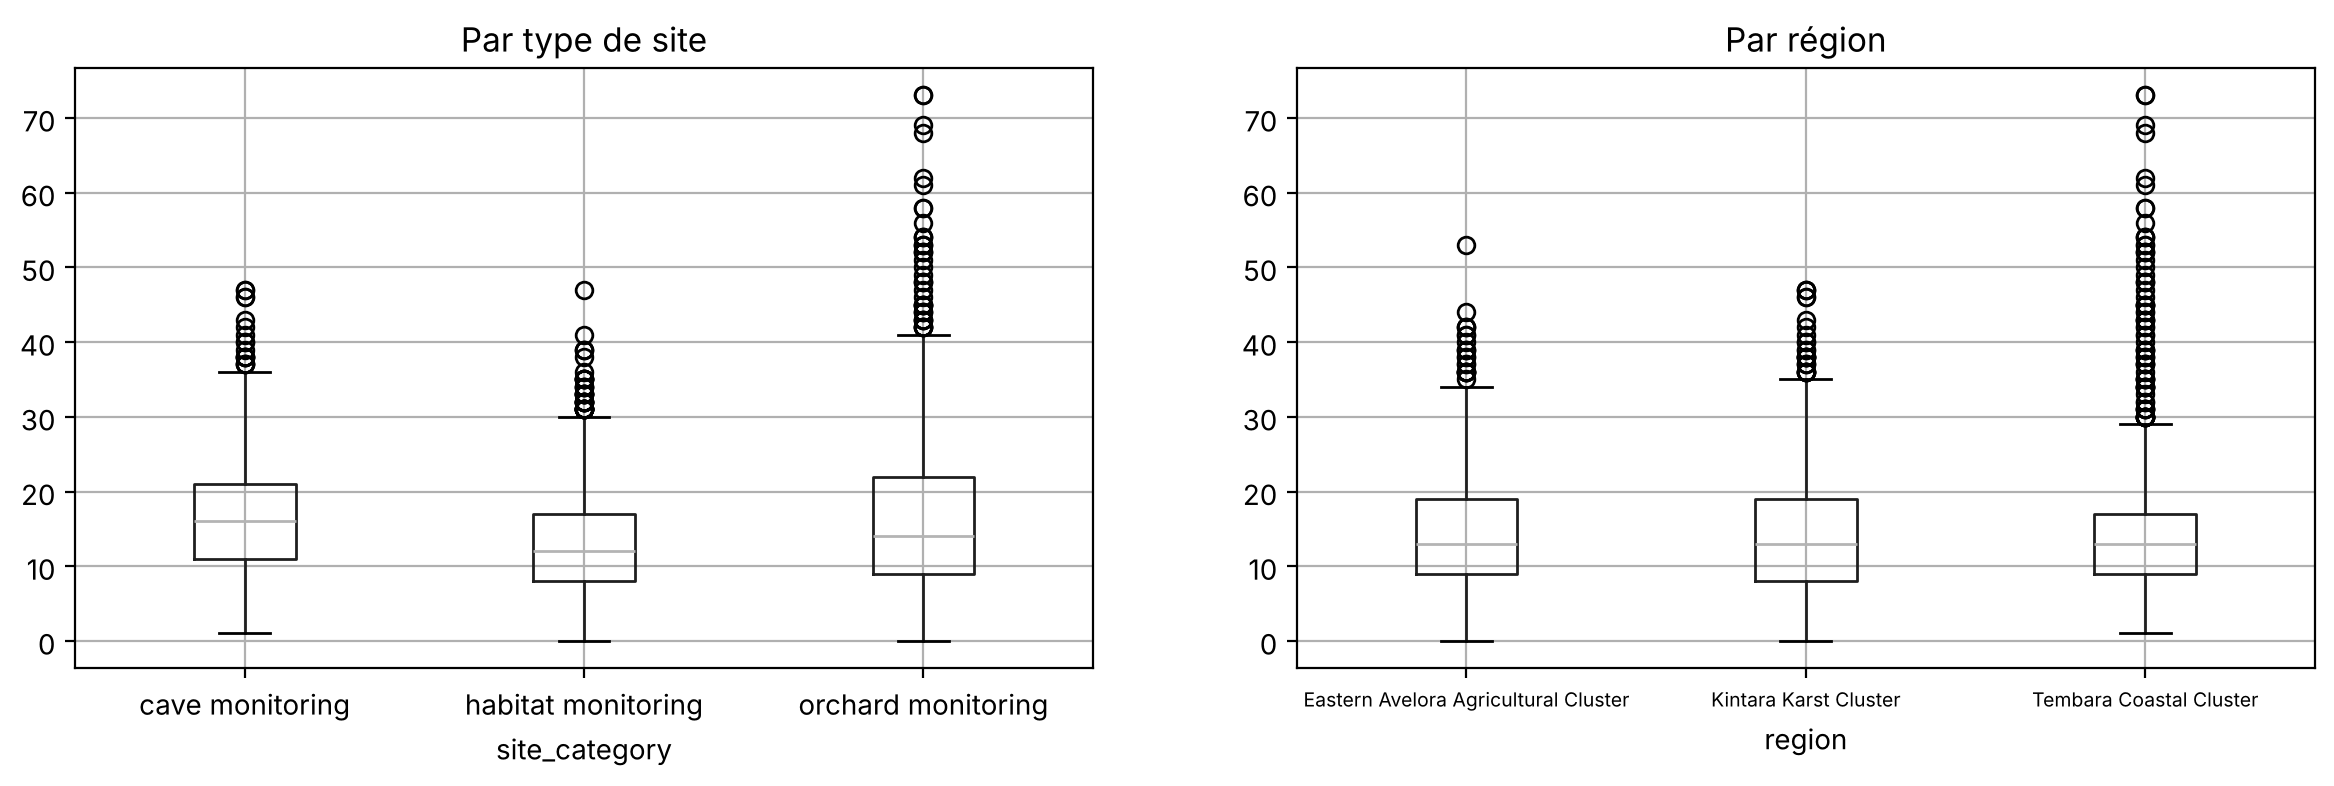

,count,mean,std,min,25%,50%,75%,max
site_category,,,,,,,,
cave monitoring,624.0,16.8,8.2,1.0,11.0,16.0,21.0,47.0
habitat monitoring,3120.0,12.7,6.6,0.0,8.0,12.0,17.0,47.0
orchard monitoring,1248.0,16.4,10.8,0.0,9.0,14.0,22.0,73.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
releves.boxplot(column="observed_bat_count", by="site_category", ax=axes[0])
releves.boxplot(column="observed_bat_count", by="region", ax=axes[1])
axes[0].set_title("Par type de site")
axes[1].set_title("Par région")
axes[1].tick_params(axis="x", labelsize=7)
plt.suptitle("")
plt.show()

releves.groupby("site_category")["observed_bat_count"].describe().round(1)

- Les grottes et les vergers ont plus de chauves-souris que les habitats naturels : les grottes servent d'abri, et les chauves-souris se nourrissent des fleurs de durian.
- Les trois régions ont à peu près le même nombre de chauves-souris.

Le type de site compte, la région non.

## 3. Piste 2 : comment le nombre évolue-t-il dans le temps ?

On trace le nombre moyen de chauves-souris pour chaque mois.

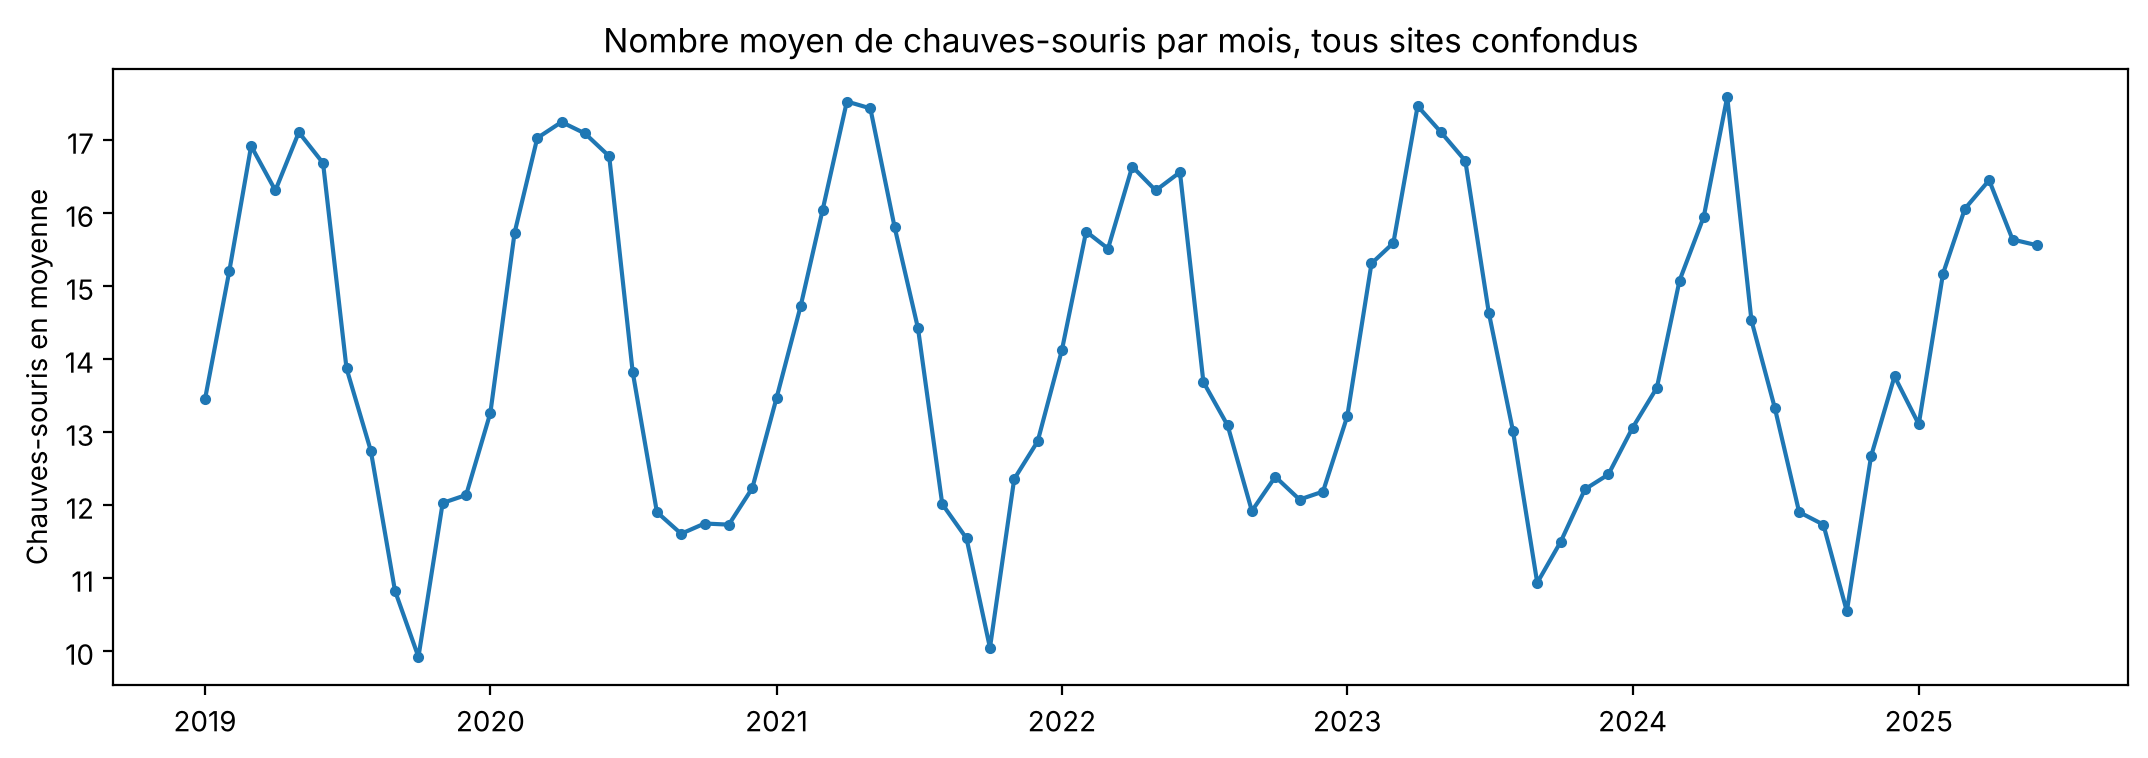

{2019: 13.9, 2020: 14.2, 2021: 14.0, 2022: 14.2, 2023: 14.2, 2024: 13.6, 2025: 15.3}


In [5]:
par_mois = releves.groupby("mois")["observed_bat_count"].mean()

plt.figure(figsize=(13, 4))
plt.plot(par_mois.index, par_mois.values, marker=".")
plt.ylabel("Chauves-souris en moyenne")
plt.title("Nombre moyen de chauves-souris par mois, tous sites confondus")
plt.show()

print(releves.groupby(releves["mois"].dt.year)["observed_bat_count"].mean().round(1).to_dict())

La courbe monte et descend chaque année, sans hausse ni baisse sur toute la période. Pour vérifier que ce mouvement se répète, on calcule l'autocorrélation : on compare la courbe avec elle-même décalée de quelques mois.

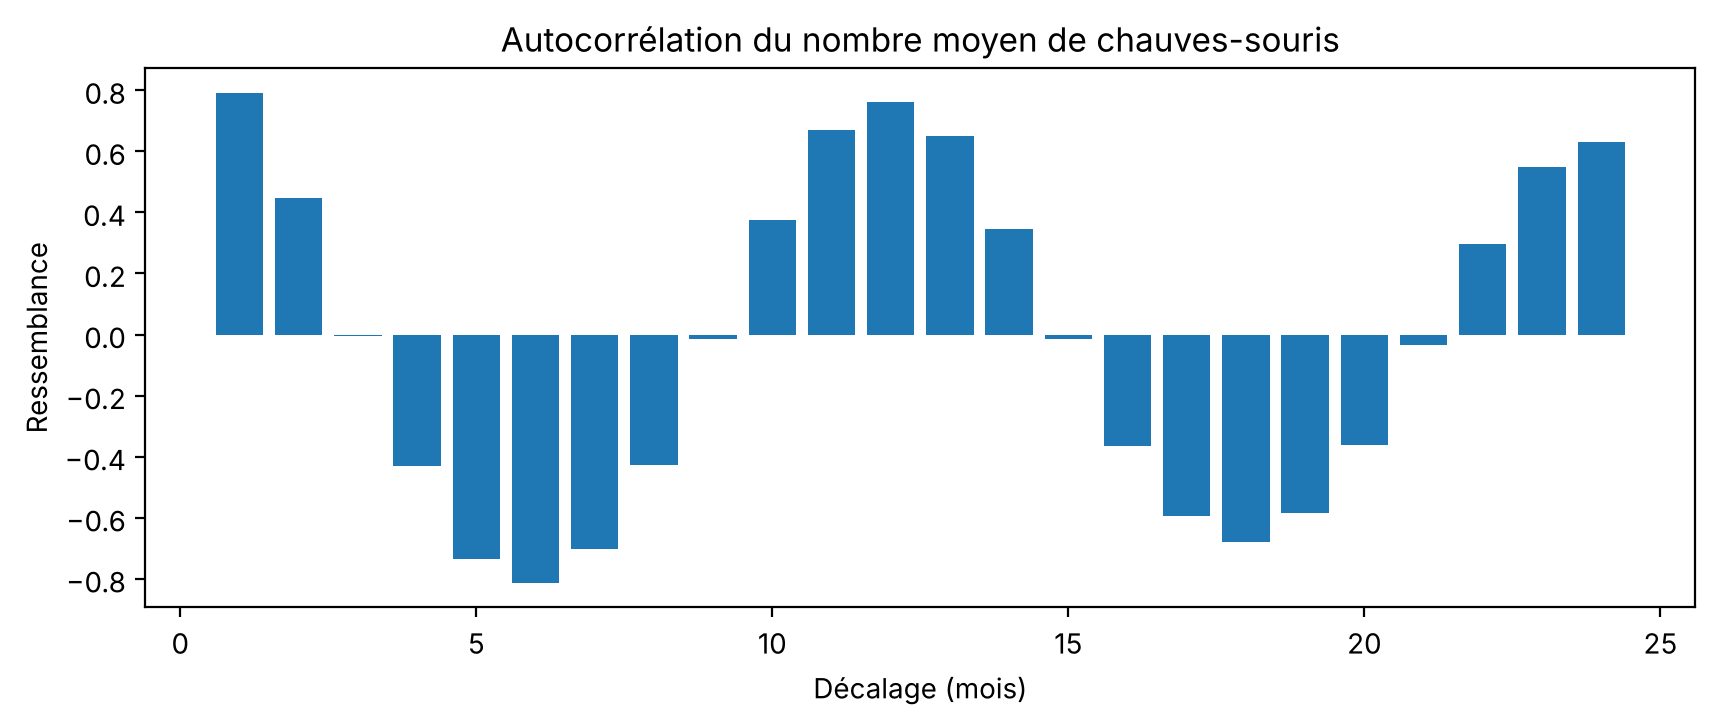

Décalage de 6 mois : -0.81
Décalage de 12 mois : 0.76


In [6]:
ecart = par_mois - par_mois.mean()
autocorrelation = [(ecart[:-k].values * ecart[k:].values).sum() / (ecart ** 2).sum() for k in range(1, 25)]

plt.figure(figsize=(10, 3.5))
plt.bar(range(1, 25), autocorrelation)
plt.xlabel("Décalage (mois)")
plt.ylabel("Ressemblance")
plt.title("Autocorrélation du nombre moyen de chauves-souris")
plt.show()

print("Décalage de 6 mois :", round(autocorrelation[5], 2))
print("Décalage de 12 mois :", round(autocorrelation[11], 2))

La courbe se ressemble beaucoup à elle-même avec 12 mois de décalage : le nombre de chauves-souris suit un cycle qui se répète chaque année. On regarde la moyenne de chaque mois pour voir ce cycle.

In [7]:
releves.groupby(releves["mois"].dt.month)["observed_bat_count"].mean().round(1).to_frame("moyenne").T

mois,1,2,3,4,5,6,7,8,9,10,11,12
moyenne,13.4,15.1,16.0,16.8,16.9,16.1,14.0,12.4,11.4,11.0,12.2,12.6


Il y a plus de chauves-souris au printemps qu'en automne : le nombre dépend de la saison.

Pour savoir si un relevé est anormal, il faudra donc le comparer à la même saison des autres années.

## 4. Piste 3 : qu'est-ce qui fait varier le nombre de chauves-souris ?

On veut savoir pourquoi le nombre de chauves-souris change d'un relevé à l'autre. Est-ce à cause de la météo, du milieu (perturbation, pesticides), ou d'un problème d'appareil ?

On mesure la corrélation entre le nombre de chauves-souris et chacun de ces éléments. On calcule à la fois Pearson et Spearman : Spearman est moins sensible aux valeurs extrêmes, donc si les deux donnent la même chose, le résultat est fiable.

In [8]:
facteurs = ["habitat_disturbance_index", "pesticide_index", "rainfall_mm", "weather_interference",
            "observation_hours", "uptime_pct", "acoustic_quality", "mean_temperature_c"]
tableau_corr = pd.DataFrame({
    "Pearson": releves[facteurs + ["observed_bat_count"]].corr()["observed_bat_count"],
    "Spearman": releves[facteurs + ["observed_bat_count"]].corr(method="spearman")["observed_bat_count"],
}).drop("observed_bat_count").sort_values("Pearson").round(2)
tableau_corr

,Pearson,Spearman
habitat_disturbance_index,-0.37,-0.38
pesticide_index,-0.25,-0.24
weather_interference,-0.23,-0.23
rainfall_mm,-0.19,-0.20
acoustic_quality,0.12,0.12
uptime_pct,0.14,0.12
mean_temperature_c,0.19,0.19
observation_hours,0.32,0.32


- Pearson et Spearman donnent les mêmes résultats.
- Plus l'habitat est perturbé ou traité aux pesticides, moins il y a de chauves-souris.
- La pluie et la gêne météo font aussi baisser les comptages.
- L'état de l'appareil compte peu.

Aucun lien n'est très fort : le nombre de chauves-souris dépend de plusieurs causes ordinaires à la fois.

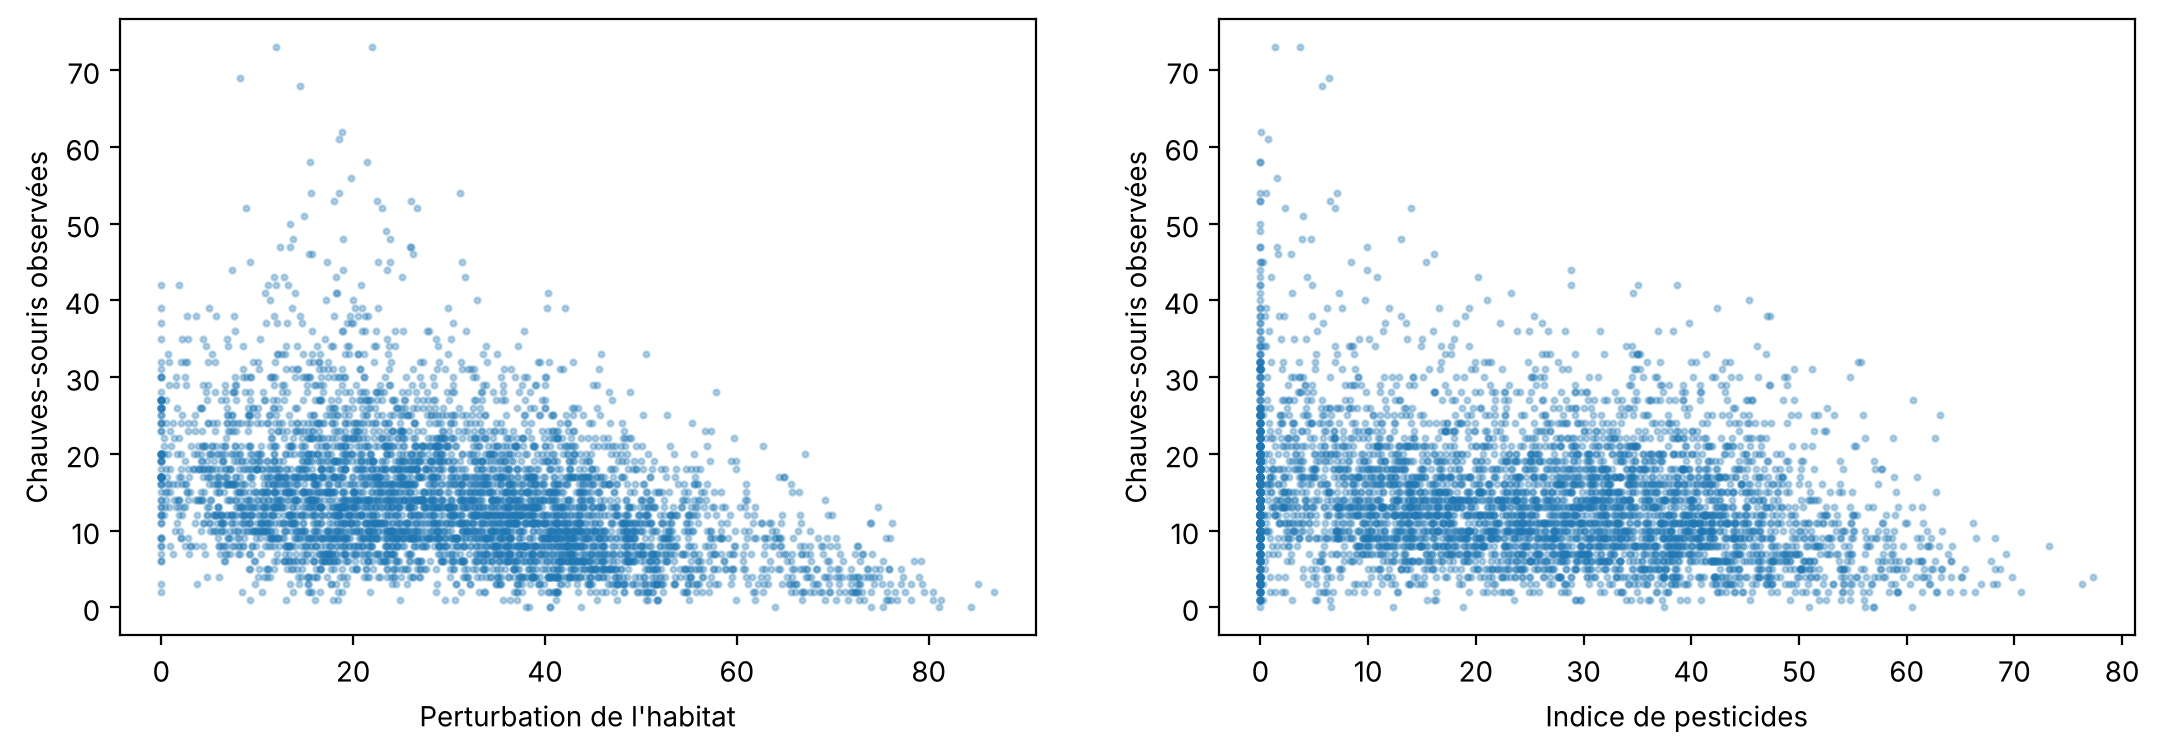

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(releves["habitat_disturbance_index"], releves["observed_bat_count"], s=4, alpha=0.3)
axes[0].set_xlabel("Perturbation de l'habitat")
axes[1].scatter(releves["pesticide_index"], releves["observed_bat_count"], s=4, alpha=0.3)
axes[1].set_xlabel("Indice de pesticides")
for ax in axes:
    ax.set_ylabel("Chauves-souris observées")
plt.show()

## 5. Piste 4 : les chauves-souris et les durians

Les chauves-souris pollinisent les fleurs de durian. On regarde si, dans les vergers, plus de chauves-souris veut dire plus de fleurs qui deviennent des fruits (le taux de nouaison).

In [10]:
vergers_mois = vergers.rename(columns={"survey_period": "mois"}).merge(
    releves[["site_code", "mois", "observed_bat_count"]], on=["site_code", "mois"])

colonnes = ["durian_flower_density", "fruit_set_rate_pct", "durian_yield_kg",
            "other_pollinator_activity", "fertilizer_use_index", "irrigation_level"]
vergers_mois[colonnes + ["observed_bat_count"]].corr()["observed_bat_count"].drop("observed_bat_count") \
    .round(2).to_frame("corrélation avec les chauves-souris")

,corrélation avec les chauves-souris
durian_flower_density,0.26
fruit_set_rate_pct,0.53
durian_yield_kg,-0.00
other_pollinator_activity,0.32
fertilizer_use_index,0.01
irrigation_level,0.05


- Plus il y a de chauves-souris, plus les fleurs deviennent des fruits.
- L'engrais et l'irrigation n'ont aucun lien avec les chauves-souris, ce qui est normal.
- La récolte en kilos n'a pas de lien, sans doute parce qu'elle dépend surtout de la taille du verger.

Rien d'étrange ici, mais on voit que les chauves-souris comptent : sans elles, les vergers produisent moins.

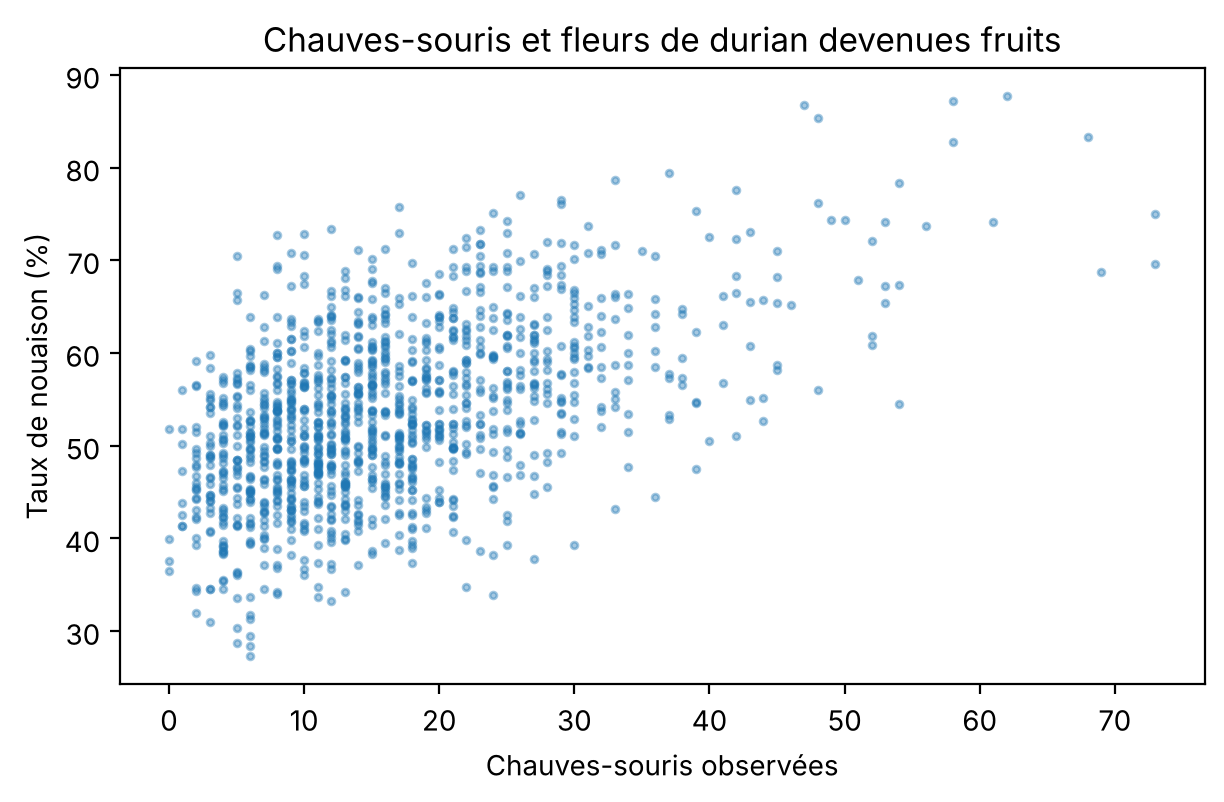

In [11]:
plt.figure(figsize=(7, 4))
plt.scatter(vergers_mois["observed_bat_count"], vergers_mois["fruit_set_rate_pct"], s=6, alpha=0.4)
plt.xlabel("Chauves-souris observées")
plt.ylabel("Taux de nouaison (%)")
plt.title("Chauves-souris et fleurs de durian devenues fruits")
plt.show()

## 6. Piste 5 : des sites qui se ressemblent ?

On résume chaque site par quelques chiffres (chauves-souris, perturbation, pesticides, pluie, force du cycle annuel) et on essaie de regrouper les sites qui se ressemblent avec K-means. Le score de silhouette dit si les groupes sont bien séparés.

In [12]:
profil_sites = releves.groupby("site_code").agg(
    chauves_souris=("observed_bat_count", "mean"),
    perturbation=("habitat_disturbance_index", "mean"),
    pesticides=("pesticide_index", "mean"),
    pluie=("rainfall_mm", "mean"))
moyennes_mensuelles = releves.groupby(["site_code", releves["mois"].dt.month])["observed_bat_count"].mean()
profil_sites["amplitude_annuelle"] = moyennes_mensuelles.groupby("site_code").agg(lambda v: v.max() - v.min())

# Les chiffres n'ont pas la même unité : on les met à la même échelle
Z = StandardScaler().fit_transform(profil_sites)

# Le score de silhouette dit si les groupes sont bien séparés (proche de 1) ou mélangés (proche de 0)
for k in [2, 3, 4, 5]:
    groupes = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)
    print(k, "groupes : silhouette =", round(silhouette_score(Z, groupes), 2))

2 groupes : silhouette = 0.3
3 groupes : silhouette = 0.22
4 groupes : silhouette = 0.2
5 groupes : silhouette = 0.21


Les scores sont faibles : les sites ne forment pas de groupes bien distincts. On prend quand même 3 groupes pour voir ce qui les sépare.

In [13]:
profil_sites["groupe"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)
profil_sites = profil_sites.join(sites.set_index("site_code")[["site_category"]])
print(profil_sites.groupby("groupe").mean(numeric_only=True).round(1))
pd.crosstab(profil_sites["groupe"], profil_sites["site_category"])

        chauves_souris  perturbation  pesticides  pluie  amplitude_annuelle
groupe                                                                     
0                  9.5          45.9        34.3  171.1                 9.1
1                 21.7          20.2        20.7  147.5                15.6
2                 13.1          25.1        20.8  159.0                 8.3


site_category,cave monitoring,habitat monitoring,orchard monitoring
groupe,,,
0,2,10,8
1,3,7,6
2,3,23,2


- Un groupe de sites très perturbés, avec peu de chauves-souris.
- Un groupe de sites peu perturbés, avec beaucoup de chauves-souris.
- Un groupe intermédiaire, surtout des habitats naturels.

Les grottes sont réparties dans les trois groupes. La piste confirme le rôle de la perturbation, mais aucun site ne ressort.

## 7. Piste 6 : des mois anormaux

On cherche des mois où un site a eu beaucoup moins de chauves-souris que d'habitude.

### Premier essai : l'IQR sur tous les relevés

In [14]:
n = releves["observed_bat_count"]
q1, q3 = n.quantile(0.25), n.quantile(0.75)
bas, haut = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print("Bornes :", bas, "et", haut)
print("Relevés sous la borne basse :", (n < bas).sum())
print("Relevés au-dessus de la borne haute :", (n > haut).sum())
releves[n > haut]["site_category"].value_counts()

Bornes : -7.0 et 33.0
Relevés sous la borne basse : 0
Relevés au-dessus de la borne haute : 128


site_category
orchard monitoring    80
cave monitoring       30
habitat monitoring    18
Name: count, dtype: int64

La borne basse est négative, donc aucun relevé ne peut être « trop bas ». L'IQR ne repère que des relevés très hauts, surtout dans les vergers. En mélangeant tous les sites et toutes les saisons, cette méthode ne trouve rien d'utile.

### Deuxième essai : comparer chaque relevé à la même saison

Pour chaque relevé, on calcule ce qu'on attendait : la médiane du même site pour le même mois de l'année. On calcule ensuite le z-score modifié de l'écart avec cette attente. Un relevé est jugé anormal en dessous de −3,5.

In [15]:
releves["attendu"] = releves.groupby(["site_code", releves["mois"].dt.month])["observed_bat_count"].transform("median")
releves["part_de_l_attendu"] = releves["observed_bat_count"] / releves["attendu"].replace(0, np.nan)
releves["ecart"] = releves["observed_bat_count"] - releves["attendu"]

def z_modifie(x):
    mad = (x - x.median()).abs().median()
    return 0.6745 * (x - x.median()) / mad

releves["z"] = releves.groupby("site_code")["ecart"].transform(z_modifie)
anormaux = releves[releves["z"] < -3.5]
print("Relevés anormalement bas :", len(anormaux))
anormaux["site_code"].value_counts()

Relevés anormalement bas : 20


site_code
KNT-QWU    5
KNT-NNM    3
AVL-NFR    2
TMB-HVD    2
TMB-NAC    1
KNT-JQG    1
KNT-YRG    1
KNT-WUQ    1
KNT-DMJ    1
TMB-GZX    1
TMB-HQL    1
TMB-QCB    1
Name: count, dtype: int64

On trouve 20 relevés anormalement bas. On regarde s'ils ont une explication simple : un événement météo, une panne, un appareil peu en marche ou un relevé de mauvaise qualité.

In [16]:
releves["explication_simple"] = (releves["weather_exception_code"].notna() | releves["fault_code"].notna()
                                 | (releves["uptime_pct"] < 70) | (releves["survey_quality"] == "limited"))
anormaux = releves[releves["z"] < -3.5]
print("Avec une explication simple :", anormaux["explication_simple"].sum())
print("Sans explication :", (~anormaux["explication_simple"]).sum())
anormaux[~anormaux["explication_simple"]][["site_code", "mois", "observed_bat_count", "attendu", "uptime_pct"]] \
    .sort_values(["site_code", "mois"])

Avec une explication simple : 4
Sans explication : 16


,site_code,mois,observed_bat_count,attendu,uptime_pct
2259,AVL-NFR,2025-04-01,8,14.0,100.0
1430,KNT-DMJ,2021-03-01,10,21.0,100.0
1039,KNT-JQG,2021-02-01,3,16.0,100.0
861,KNT-NNM,2019-04-01,8,20.0,95.4
934,KNT-NNM,2025-05-01,4,16.0,91.4
1565,KNT-QWU,2019-06-01,7,16.0,81.2
1572,KNT-QWU,2020-01-01,4,12.0,95.4
1589,KNT-QWU,2021-06-01,7,16.0,98.1
1613,KNT-QWU,2023-06-01,9,16.0,98.1
1353,KNT-WUQ,2021-04-01,7,23.0,85.7


- 16 relevés restent sans explication simple.
- Ils sont éparpillés sur 11 sites et sur toutes les années.

Ça ressemble à des variations normales. La méthode a aussi une limite : elle ne repère que les chutes très fortes, et rate les baisses plus modérées.

## 8. Piste 7 : quelles situations vont avec une forte baisse ?

On change de question : dans quelles situations le nombre de chauves-souris chute-t-il fortement ? On utilise les règles d'association.

On décrit chaque relevé par des situations vraies ou fausses : forte baisse (moins de la moitié de l'attendu), habitat très perturbé, beaucoup de pesticides, forte gêne météo, événement météo, panne, relevé de qualité limitée, grotte à accès contrôlé.

In [17]:
situations = pd.DataFrame({
    "forte baisse": releves["part_de_l_attendu"] < 0.5,
    "habitat très perturbé": releves["habitat_disturbance_index"] > releves["habitat_disturbance_index"].quantile(0.75),
    "beaucoup de pesticides": releves["pesticide_index"] > releves["pesticide_index"].quantile(0.75),
    "forte gêne météo": releves["weather_interference"] > releves["weather_interference"].quantile(0.75),
    "événement météo": releves["weather_exception_code"].notna(),
    "panne d'appareil": releves["fault_code"].notna(),
    "relevé de qualité limitée": releves["survey_quality"] == "limited",
    "grotte à accès contrôlé": releves["cave_access_category"] == "managed",
})
print("Part des relevés en forte baisse :", round(situations["forte baisse"].mean(), 3))
print("Nombre de relevés en forte baisse :", situations["forte baisse"].sum())

Part des relevés en forte baisse : 0.054
Nombre de relevés en forte baisse : 270


On cherche des règles « si telle situation, alors forte baisse », avec trois mesures :
- le support : la part des relevés où les deux arrivent ensemble ;
- la confiance : parmi les relevés dans cette situation, la part en forte baisse ;
- le lift : combien de fois la forte baisse est plus fréquente que d'habitude (1 = aucun lien).

On teste les situations seules, puis par deux, en gardant seulement celles qui arrivent au moins 20 fois.

In [18]:
from itertools import combinations

baisse = situations["forte baisse"]
causes = [c for c in situations.columns if c != "forte baisse"]

regles = []
for taille in [1, 2]:
    for groupe in combinations(causes, taille):
        si = situations[list(groupe)].all(axis=1)
        if si.sum() < 20:
            continue
        confiance = (si & baisse).sum() / si.sum()
        regles.append({"si": " + ".join(groupe),
                       "relevés concernés": int(si.sum()),
                       "support": round((si & baisse).mean(), 3),
                       "confiance": round(confiance, 2),
                       "lift": round(confiance / baisse.mean(), 2)})

regles = pd.DataFrame(regles).sort_values("lift", ascending=False)
regles.head(12)

,si,relevés concernés,support,confiance,lift
16,beaucoup de pesticides + relevé de qualité lim...,26,0.002,0.38,7.11
15,beaucoup de pesticides + panne d'appareil,30,0.002,0.37,6.78
24,panne d'appareil + grotte à accès contrôlé,24,0.001,0.21,3.85
20,forte gêne météo + relevé de qualité limitée,39,0.002,0.21,3.79
10,habitat très perturbé + panne d'appareil,65,0.003,0.20,3.70
11,habitat très perturbé + relevé de qualité limitée,56,0.002,0.18,3.30
4,panne d'appareil,189,0.006,0.17,3.13
5,relevé de qualité limitée,138,0.005,0.17,3.08
23,panne d'appareil + relevé de qualité limitée,126,0.004,0.17,3.08
19,forte gêne météo + panne d'appareil,49,0.002,0.16,3.02


- Les meilleures règles associent des pesticides à une panne ou à un relevé de mauvaise qualité. Mais elles concernent peu de relevés, et une panne veut surtout dire qu'on a mal compté.
- Seules, la perturbation, les pesticides et la météo augmentent un peu le risque de forte baisse, sans l'expliquer.

On regarde aussi combien de fortes baisses ont au moins une de ces explications.

In [19]:
au_moins_une = situations[causes].drop(columns="grotte à accès contrôlé").any(axis=1)
print("Fortes baisses avec au moins une explication ordinaire :", round(au_moins_une[baisse].mean(), 2))
print("Même part pour l'ensemble des relevés :", round(au_moins_une.mean(), 2))

Fortes baisses avec au moins une explication ordinaire : 0.77
Même part pour l'ensemble des relevés : 0.58


- Les explications ordinaires sont un peu plus fréquentes lors des fortes baisses, mais elles sont aussi très courantes en temps normal.
- Près d'un quart des fortes baisses n'ont aucune explication.

Les causes ordinaires ne suffisent donc pas à expliquer toutes les baisses.

## 9. Piste 8 : les grottes à accès contrôlé

Huit grottes ne sont accessibles qu'avec une autorisation. On regarde si les chauves-souris y sont moins nombreuses que prévu, à cause du passage de personnes.

In [20]:
releves.groupby("cave_access_category")["part_de_l_attendu"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
cave_access_category,,,,,,,,
managed,624.0,1.00,0.36,0.07,0.78,1.0,1.16,2.80
not applicable,4368.0,1.03,0.39,0.00,0.80,1.0,1.20,5.67


Ces grottes ont autant de chauves-souris que prévu, comme les autres sites. Prises dans leur ensemble, elles n'ont rien de particulier.

## 10. Piste 9 : les rapports de terrain

Il reste les 30 rapports des équipes de terrain. Beaucoup ont l'air de se répéter. On mesure leur ressemblance avec TF-IDF et la similarité cosinus : pour chaque rapport, on garde la similarité avec le rapport qui lui ressemble le plus.

In [21]:
mots = TfidfVectorizer(stop_words="english").fit_transform(rapports["text"])
similarite = cosine_similarity(mots)
np.fill_diagonal(similarite, np.nan)
rapports["plus_proche_voisin"] = np.nanmax(similarite, axis=1).round(2)
rapports.sort_values("plus_proche_voisin")[["document_id", "site_code", "document_date",
                                            "document_type", "author_organization",
                                            "plus_proche_voisin"]].head(8)

,document_id,site_code,document_date,document_type,author_organization,plus_proche_voisin
0,EFR-510088,KNT-KES,2024-04-02,ecological_incident_report,Horizon Field Research Cooperative,0.20
1,EFR-510082,KNT-JAK,2019-04-01,field_observation,Pollinator Justice Network,0.67
3,EFR-510007,KNT-JQG,2025-02-15,field_observation,Varlan Natural History Circle,0.76
8,EFR-510037,KNT-YRG,2024-03-23,monitoring_report,Threshold Earth Observatory,0.78
16,EFR-510109,KNT-GGN,2024-07-25,cave_access_note,Belen Agro-Industries,0.78
9,EFR-510054,KNT-YRG,2019-08-03,monitoring_report,Belen Agro-Industries,0.79
25,EFR-510077,KNT-TEX,2019-04-07,ecological_incident_report,Horizon Field Research Cooperative,0.79
7,EFR-510026,KNT-CHP,2021-10-16,monitoring_report,Lantern Investigative Bureau,0.79


Tous les rapports ont un « jumeau » très proche, sauf un : EFR-510088, écrit à KNT-KES en avril 2024. C'est le seul qui ne suit pas le modèle habituel. On le lit.

In [22]:
print(rapports.loc[rapports["document_id"] == "EFR-510088", "text"].iloc[0])

INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.

IMMEDIATE ACTION
The entrance was photographed, the cut material was retained, and the station configuration was checked against the prior record. A repeat survey and a comparison with adjacent

Le rapport dit que :
- après une entrée dans la grotte en mars, une espèce de chauve-souris a nettement baissé ;
- l'appareil marchait et la météo n'explique pas la baisse ;
- on a trouvé des traces de manipulation et des liens coupés ;
- une équipe autorisée est entrée avec du matériel, officiellement pour de la maintenance.

Le rapport ne dit pas qui est entré. On vérifie la baisse dans nos relevés.

In [23]:
kes = releves[(releves["site_code"] == "KNT-KES") & releves["mois"].between("2024-01-01", "2024-08-01")]
kes[["mois", "observed_bat_count", "attendu", "z", "uptime_pct", "fault_code"]].round({"z": 2})

,mois,observed_bat_count,attendu,z,uptime_pct,fault_code
60,2024-01-01,17,17.0,0.00,93.1,NaN
61,2024-02-01,21,21.0,0.00,92.4,NaN
62,2024-03-01,16,23.0,-1.05,88.7,NaN
63,2024-04-01,10,22.0,-1.80,83.1,NaN
64,2024-05-01,3,23.0,-3.00,91.8,NaN
65,2024-06-01,14,21.0,-1.05,100.0,NaN
66,2024-07-01,11,16.5,-0.82,88.3,NaN
67,2024-08-01,5,11.5,-0.97,91.8,NaN


- En avril et mai 2024, on compte beaucoup moins de chauves-souris que prévu, avec un appareil qui fonctionne.
- La piste 6 ne l'avait pas repéré, parce que la baisse n'est pas assez extrême pour le z-score.

Il s'est donc passé quelque chose à KNT-KES après l'entrée d'une équipe autorisée. Mais l'écologie ne dit pas qui est entré. Il faut chercher ailleurs :
- dans public records, qui peut contenir les autorisations d'accès aux sites ;
- dans la logistique, qui peut montrer du matériel envoyé vers les sites.

Avec les dates d'entrée, on pourra vérifier si les chauves-souris baissent après chaque entrée, et si ça dépend de qui entre.

## 11. Bilan

Ce qu'on a appris :
- Les chauves-souris sont plus nombreuses dans les grottes et les vergers.
- Leur nombre suit un cycle d'un an.
- Il baisse avec la perturbation et les pesticides ; les appareils comptent peu.
- Elles aident les durians à donner des fruits.

Les pistes sans résultat :
- Le regroupement des sites ne fait ressortir aucun site.
- L'IQR et le z-score ne trouvent pas de mois anormaux qui se tiennent.
- Les causes ordinaires n'expliquent pas toutes les fortes baisses.
- Les grottes à accès contrôlé ne sont pas différentes des autres sites.

Ce qui est pertinent :
- Un seul rapport sort du lot : il décrit une baisse de chauves-souris à KNT-KES après l'entrée d'une équipe autorisée, avec des traces de manipulation.
- Nos relevés confirment cette baisse.

À chercher ailleurs :
- Qui est entré sur les sites, et quand ? (public records)
- Du matériel envoyé vers les grottes ? (logistique)